In [ ]:
!pip install -q git+https://github.com/huggingface/transformers.git datasets
!pip install -q evaluate

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 542.0/542.0 kB 11.3 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 116.3/116.3 kB 6.5 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 194.1/194.1 kB 14.8 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 134.8/134.8 kB 15.2 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 84.1/84.1 kB 2.3 MB/s eta 0:00:00


In [ ]:
!pip show torch
!pip show torchvision
!pip show datasets
!pip show albumentations

Name: torch
Version: 2.3.0+cu121
Summary: Tensors and Dynamic neural networks in Python with strong GPU acceleration
Home-page: https://pytorch.org/
Author: PyTorch Team
Author-email: packages@pytorch.org
License: BSD-3
Location: /usr/local/lib/python3.10/dist-packages
Requires: filelock, fsspec, jinja2, networkx, nvidia-cublas-cu12, nvidia-cuda-cupti-cu12, nvidia-cuda-nvrtc-cu12, nvidia-cuda-runtime-cu12, nvidia-cudnn-cu12, nvidia-cufft-cu12, nvidia-curand-cu12, nvidia-cusolver-cu12, nvidia-cusparse-cu12, nvidia-nccl-cu12, nvidia-nvtx-cu12, sympy, triton, typing-extensions
Required-by: fastai, torchaudio, torchtext, torchvision
Name: torchvision
Version: 0.18.0+cu121
Summary: image and video datasets and models for torch deep learning
Home-page: https://github.com/pytorch/vision
Author: PyTorch Core Team
Author-email: soumith@pytorch.org
License: BSD
Location: /usr/local/lib/python3.10/dist-packages
Requires: numpy, pillow, torch
Required-by: fastai
Name: datasets
Version: 2.19.1
Summ

In [ ]:
!pip show transformers

Name: transformers
Version: 4.42.0.dev0
Summary: State-of-the-art Machine Learning for JAX, PyTorch and TensorFlow
Home-page: https://github.com/huggingface/transformers
Author: The Hugging Face team (past and future) with the help of all our contributors (https://github.com/huggingface/transformers/graphs/contributors)
Author-email: transformers@huggingface.co
License: Apache 2.0 License
Location: /usr/local/lib/python3.10/dist-packages
Requires: filelock, huggingface-hub, numpy, packaging, pyyaml, regex, requests, safetensors, tokenizers, tqdm
Required-by: 


## Load dataset

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
import shutil

# Replace with the actual path to your ZIP archive
zip_file_path = "/content/drive/MyDrive/KCDH/data_S1.zip"

# Define the target directory for extraction
target_dir = "/content/data_S1"  # Replace with your desired extraction location

try:
  # Extract the archive using shutil.unpack_archive
  shutil.unpack_archive(zip_file_path, target_dir, "zip")
  print(f"Extracted archive to {target_dir}")
except Exception as e:
  print(f"Error during extraction: {e}")


Extracted archive to /content/data_S1


In [ ]:
import shutil

# Define the path of the directory you want to delete
directory_path = '/content/drive/MyDrive/custom_data_S1'

# Remove the directory and its contents
shutil.rmtree(directory_path)

In [ ]:
import os

data_S1_path = r"/content/data_S1/data_S1"  # Adjust the path as needed

if os.path.exists(data_S1_path):
    print(f"The path '{data_S1_path}' exists.")
else:
    print(f"The path '{data_S1_path}' does not exist.")


The path '/content/data_S1/data_S1' exists.


In [ ]:
import os
import cv2

# Function to crop and save images
def crop_and_save_images(images_path, labels_path, save_images_path, save_labels_path):
    # Check if directories already exist
    if os.path.exists(save_images_path) and os.path.exists(save_labels_path):
        print(f"Directories {save_images_path} and {save_labels_path} already exist")
        return
    else:
        os.makedirs(save_images_path, exist_ok=True)
        os.makedirs(save_labels_path, exist_ok=True)

    # Get list of image files
    image_files = sorted(os.listdir(images_path))
    label_files = sorted(os.listdir(labels_path))

    print(f"Found {len(image_files)} image files and {len(label_files)} label files")

    for image_file, label_file in zip(image_files, label_files):
        # Read images
        image_path = os.path.join(images_path, image_file)
        label_path = os.path.join(labels_path, label_file)
        print(f"Processing {image_path} and {label_path}")

        image = cv2.imread(image_path, cv2.IMREAD_UNCHANGED)
        label = cv2.imread(label_path, cv2.IMREAD_UNCHANGED)

        if image is None:
            print(f"Error reading image file: {image_path}")
            continue
        if label is None:
            print(f"Error reading label file: {label_path}")
            continue

        # Get dimensions
        height, width = image.shape[:2]
        crop_size = 448  # Adjust crop size as needed

        print(f"Image dimensions (height, width): ({height}, {width})")

        # Calculate number of crops
        num_vertical = height // crop_size
        num_horizontal = width // crop_size

        print(f"Number of vertical crops: {num_vertical}, number of horizontal crops: {num_horizontal}")

        # Crop and save
        for i in range(num_vertical):
            for j in range(num_horizontal):
                crop_image = image[i*crop_size:(i+1)*crop_size, j*crop_size:(j+1)*crop_size]
                crop_label = label[i*crop_size:(i+1)*crop_size, j*crop_size:(j+1)*crop_size]

                crop_image_filename = os.path.join(save_images_path, f"{image_file[:-4]}_{i}_{j}.png")
                crop_label_filename = os.path.join(save_labels_path, f"{label_file[:-4]}_{i}_{j}.png")

                cv2.imwrite(crop_image_filename, crop_image)
                cv2.imwrite(crop_label_filename, crop_label)

                print(f"Saved cropped image: {crop_image_filename}")
                print(f"Saved cropped label: {crop_label_filename}")

# Paths (replace with actual paths)
data_S1_path = r"/content/data_S1/data_S1"  # Assuming your dataset is in "data_S1" folder
custom_data_S1_path = r"drive/MyDrive/custom_data_S1"  # Assuming your custom dataset folder is also on MyDrive

train_images_path = os.path.join(data_S1_path, "train", "images")
train_labels_path = os.path.join(data_S1_path, "train", "labels")
test_images_path = os.path.join(data_S1_path, "test", "images")
test_labels_path = os.path.join(data_S1_path, "test", "labels")

# Define subfolders for cropped data within custom_data
custom_train_images_path = os.path.join(custom_data_S1_path, "train", "images")
custom_train_labels_path = os.path.join(custom_data_S1_path, "train", "labels")
custom_test_images_path = os.path.join(custom_data_S1_path, "test", "images")
custom_test_labels_path = os.path.join(custom_data_S1_path, "test", "labels")

# Verify the paths exist before proceeding
def verify_path(path):
    if os.path.exists(path):
        print(f"The path '{path}' exists.")
    else:
        print(f"The path '{path}' does not exist.")

# Verify all paths
verify_path(train_images_path)
verify_path(train_labels_path)
verify_path(test_images_path)
verify_path(test_labels_path)






The path '/content/data_S1/data_S1/train/images' exists.
The path '/content/data_S1/data_S1/train/labels' exists.
The path '/content/data_S1/data_S1/test/images' exists.
The path '/content/data_S1/data_S1/test/labels' exists.


In [ ]:
# Crop and save images
# Crop and save training data
crop_and_save_images(train_images_path, train_labels_path, custom_train_images_path, custom_train_labels_path)

# Crop and save testing data (if needed)
crop_and_save_images(test_images_path, test_labels_path, custom_test_images_path, custom_test_labels_path)


print("Custom data created successfully.")

Directories drive/MyDrive/custom_data_S1/train/images and drive/MyDrive/custom_data_S1/train/labels already exist
Directories drive/MyDrive/custom_data_S1/test/images and drive/MyDrive/custom_data_S1/test/labels already exist
Custom data created successfully.


Image path: drive/MyDrive/custom_data_S1/train/images/train_channel_2_3_7.png
Label path: drive/MyDrive/custom_data_S1/train/labels/train_mask_2_3_7.png


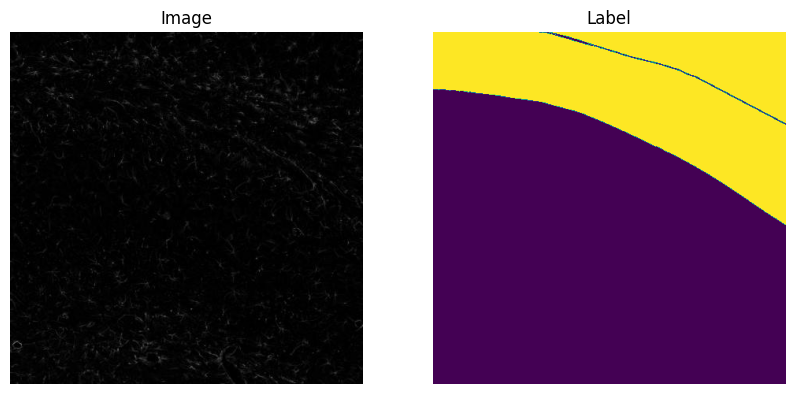

In [ ]:
import matplotlib.pyplot as plt
import cv2
import numpy as np

# ... (rest of your code)

# Display corresponding train image and its label as an example
try:
  image_path = os.path.join(custom_train_images_path, "train_channel_2_3_7.png")
  label_path = os.path.join(custom_train_labels_path, "train_mask_2_3_7.png")

  # Print paths for verification (optional)
  print(f"Image path: {image_path}")
  print(f"Label path: {label_path}")

  # Load images with error handling
  image = cv2.imread(image_path, cv2.IMREAD_UNCHANGED)
  label = cv2.imread(label_path, cv2.IMREAD_UNCHANGED)

  # Check if images were loaded successfully
  if image is not None and label is not None:
    # display them
    plt.figure(figsize=(10, 10))
    plt.subplot(1, 2, 1)
    plt.imshow(np.array(image))
    plt.title("Image")
    plt.axis("off")
    plt.subplot(1, 2, 2)
    plt.imshow(np.array(label))
    plt.title("Label")
    plt.axis("off")
    plt.show()
  else:
    print("Error loading image or label. Skipping display.")
except Exception as e:
  print(f"Unexpected error: {e}")




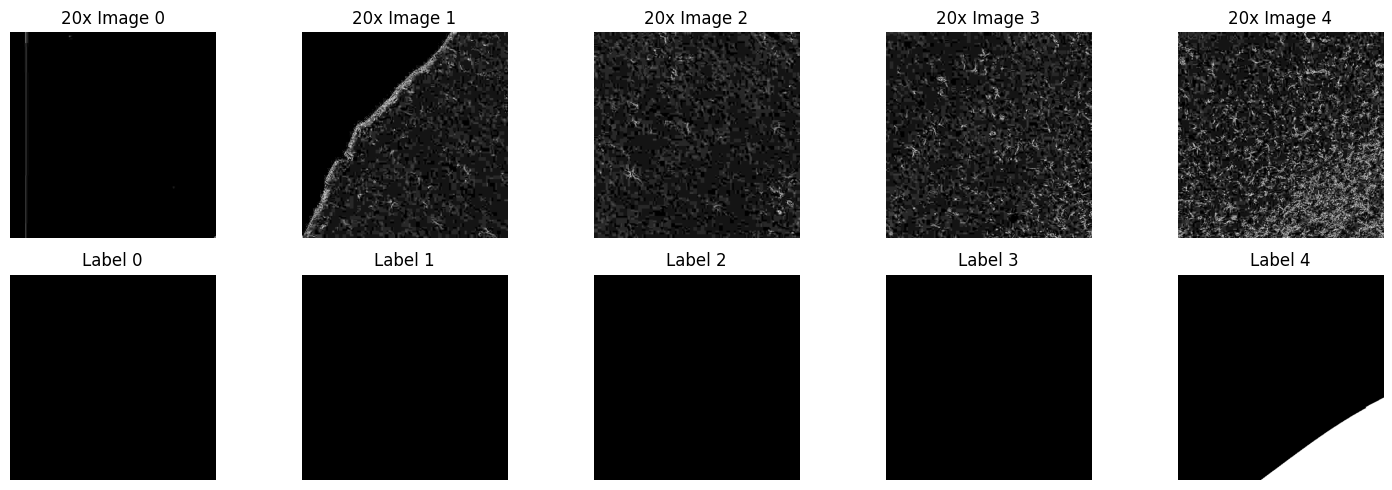

In [ ]:
# visualize 5 images in a row with corresponding labels
plt.figure(figsize=(15, 5))
for i in range(5):
    image = cv2.imread(os.path.join(custom_train_images_path, f"train_channel_2_3_{i}.png"), cv2.IMREAD_UNCHANGED)
    label = cv2.imread(os.path.join(custom_train_labels_path, f"train_mask_2_3_{i}.png"), cv2.IMREAD_UNCHANGED)
    plt.subplot(2, 5, i+1)
    plt.imshow(20*np.array(image))
    plt.title(f"20x Image {i}")
    plt.axis("off")
    plt.subplot(2, 5, i+6)
    plt.imshow(np.array(label), cmap="gray")
    plt.title(f"Label {i}")
    plt.axis("off")
    # tight_layout
plt.tight_layout()
plt.show()

In [ ]:
from datasets import Dataset, DatasetDict
from PIL import Image
import os

# Function to load images and labels from directory
def load_data(directory, flip=False):
    images = []
    labels = []
    image_dir = os.path.join(directory, "images")
    label_dir = os.path.join(directory, "labels")
    image_files = sorted(os.listdir(image_dir))
    label_files = sorted(os.listdir(label_dir))
    for image_file, label_file in zip(image_files, label_files):
        # Assuming image and label files have corresponding names
        image_path = os.path.join(image_dir, image_file)
        label_path = os.path.join(label_dir, label_file)
        image = Image.open(image_path)
        label = Image.open(label_path)
        images.append(image)
        labels.append(label)
    if flip:
        # Flip validation data
        images = [img.transpose(Image.FLIP_LEFT_RIGHT) for img in images]
        labels = [lbl.transpose(Image.FLIP_LEFT_RIGHT) for lbl in labels]
    return {"image": images, "label": labels}

# # Load train and validation data
# train_data = load_data("../data/data_S1/train")
# validation_data = load_data("../data/data_S1/test", flip=True)

# Load train and validation data (custom data)
train_data = load_data('/content/drive/MyDrive/custom_data_S1/train')
validation_data = load_data('/content/drive/MyDrive/custom_data_S1/test' , flip=True)

# Create DatasetDict
dataset_dict = DatasetDict({
    "train": Dataset.from_dict(train_data),
    "validation": Dataset.from_dict(validation_data)
})

Let's take a look at the dataset in more detail. It has a train and validation split:

In [ ]:

dataset_dict

DatasetDict({
    train: Dataset({
        features: ['image', 'label'],
        num_rows: 819
    })
    validation: Dataset({
        features: ['image', 'label'],
        num_rows: 819
    })
})

In [ ]:
dataset_dict['train'][1]

{'image': <PIL.PngImagePlugin.PngImageFile image mode=RGB size=448x448>,
 'label': <PIL.PngImagePlugin.PngImageFile image mode=L size=448x448>}

Let's take a look at the first training example:

In [ ]:
example = dataset_dict["train"][1]
image = example["image"]
# image

In [ ]:
segmentation_map = example["label"]
# segmentation_map

In [ ]:
enhanced_segmentation_map = segmentation_map.point(lambda p: p*25)
# enhanced_segmentation_map

In case of semantic segmentation, every pixel is labeled with a certain class. 0 is the "background" class.

array([[0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0],
       ...,
       [0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0]], dtype=uint8)
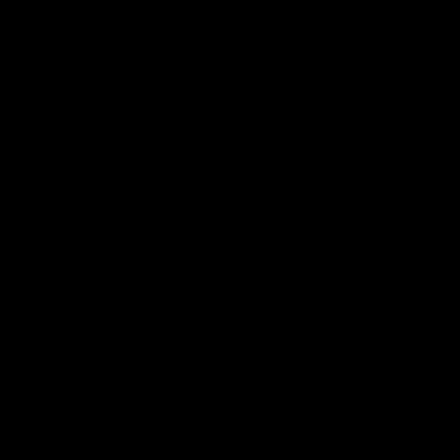

In [ ]:
import numpy as np

segmentation_map = np.array(segmentation_map)
segmentation_map

Let's load the mappings between integers and their classes (I got that from the [dataset card](https://huggingface.co/datasets/EduardoPacheco/FoodSeg103#data-categories) and asked an LLM to turn it into a dictionary).

In [ ]:
id2label = {
    0: "id_bg",
    1: "id_1",
    2: "id_2",
    3: "id_3",
    4: "id_4",
    5: "id_5",
    6: "id_6",
    7: "id_7",
    8: "id_8",
    9: "id_9",
    10: "id_10",
}

In [ ]:
print(id2label)

{0: 'id_bg', 1: 'id_1', 2: 'id_2', 3: 'id_3', 4: 'id_4', 5: 'id_5', 6: 'id_6', 7: 'id_7', 8: 'id_8', 9: 'id_9', 10: 'id_10'}


We can visualize the segmentation map on top of the image, like so:

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap

# # map every class to a random color
# id2color = {k: list(np.random.choice(range(256), size=3)) for k,v in id2label.items()}
# id2color[0] = [0,0,0] # setting bg as black color
# id2color

# map every class to a random color
cmap = plt.cm.get_cmap('viridis')  # Choose any colormap you prefer
num_classes = 11
colors = [cmap(i / num_classes) for i in range(num_classes)]
id2color = {i: [int(c * 255) for c in color[:3]] for i, color in enumerate(colors)}
id2color[0] = [0, 0, 0]  # Setting background as black color
id2color

<ipython-input-86-9cc0cd10219c>:11: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed two minor releases later. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap(obj)`` instead.
  cmap = plt.cm.get_cmap('viridis')  # Choose any colormap you prefer


{0: [0, 0, 0],
 1: [72, 33, 114],
 2: [66, 61, 132],
 3: [56, 87, 140],
 4: [45, 111, 142],
 5: [36, 133, 141],
 6: [30, 154, 137],
 7: [42, 176, 126],
 8: [81, 196, 104],
 9: [134, 212, 73],
 10: [194, 223, 34]}

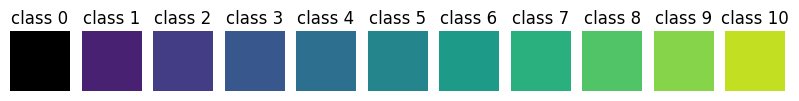

In [ ]:
# display the colors for each class with their class IDs
plt.figure(figsize=(10, 2))
for i, (class_id, color) in enumerate(id2color.items()):
    plt.subplot(1, num_classes, i + 1)
    plt.imshow([[color]])
    plt.title(f"class {class_id}")
    plt.axis("off")
plt.show()

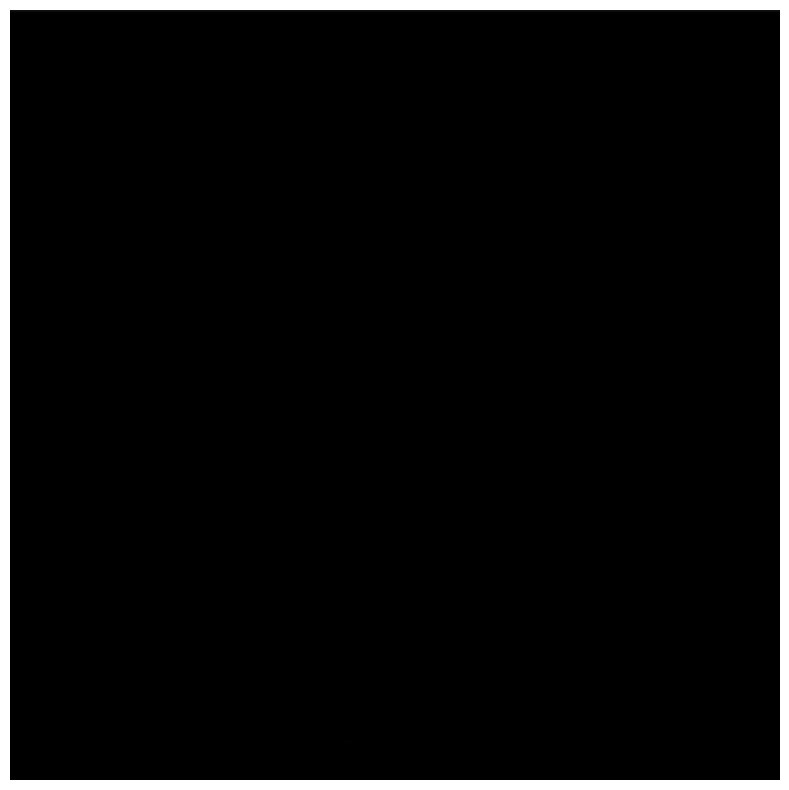

In [ ]:
def visualize_map(image, segmentation_map):
    color_seg = np.zeros((segmentation_map.shape[0], segmentation_map.shape[1], 3), dtype=np.uint8) # height, width, 3
    for label, color in id2color.items():
        color_seg[segmentation_map == label, :] = color

    # Show image + mask
    img = np.array(image) * 1 + color_seg * 0.5
    img = img.astype(np.uint8)

    plt.figure(figsize=(15, 10))
    plt.imshow(img)
    plt.axis('off')
    plt.show()

visualize_map(image, segmentation_map)

## Create PyTorch dataset

In [ ]:
from torch.utils.data import Dataset
import torch

class SegmentationDataset(Dataset):
  def __init__(self, dataset, transform):
    self.dataset = dataset
    self.transform = transform

  def __len__(self):
    return len(self.dataset)

  def __getitem__(self, idx):
    item = self.dataset[idx]
    original_image = np.array(item["image"])
    original_segmentation_map = np.array(item["label"])

    transformed = self.transform(image=original_image, mask=original_segmentation_map)
    image, target = torch.tensor(transformed['image']), torch.LongTensor(transformed['mask'])

    # convert to C, H, W
    image = image.permute(2,0,1)

    return image, target, original_image, original_segmentation_map

Let's create the training and validation datasets (note that we only randomly crop for training images).

In [ ]:
import albumentations as A

ADE_MEAN = np.array([123.675, 116.280, 103.530]) / 255
ADE_STD = np.array([58.395, 57.120, 57.375]) / 255

train_transform = A.Compose([
    # hadded an issue with an image being too small to crop, PadIfNeeded didn't help...
    # if anyone knows why this is happening I'm happy to read why
    # A.PadIfNeeded(min_height=448, min_width=448),
    # A.RandomResizedCrop(height=448, width=448),
    A.Resize(width=448, height=448),
    A.HorizontalFlip(p=0.5),
    A.Normalize(mean=ADE_MEAN, std=ADE_STD),
], is_check_shapes=False)

val_transform = A.Compose([
    A.Resize(width=448, height=448),
    A.Normalize(mean=ADE_MEAN, std=ADE_STD),

], is_check_shapes=False)

train_dataset = SegmentationDataset(dataset_dict["train"], transform=train_transform)
val_dataset = SegmentationDataset(dataset_dict["validation"], transform=val_transform)

In [ ]:
pixel_values, target, original_image, original_segmentation_map = train_dataset[3]
print(pixel_values.shape)
print(target.shape)

torch.Size([3, 448, 448])
torch.Size([448, 448])


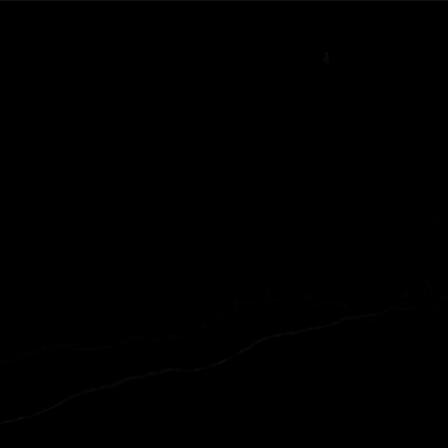

In [ ]:
Image.fromarray(original_image)

In [ ]:
[id2label[id] for id in np.unique(original_segmentation_map).tolist()]

['id_bg']

## Create PyTorch dataloaders

Next, we create PyTorch dataloaders, which allow us to get batches of data (as neural networks are trained on batches using stochastic gradient descent or SGD). We just stack the various images and labels along a new batch dimension.

In [ ]:
from torch.utils.data import DataLoader

def collate_fn(inputs):
    batch = dict()
    batch["pixel_values"] = torch.stack([i[0] for i in inputs], dim=0)
    batch["labels"] = torch.stack([i[1] for i in inputs], dim=0)
    batch["original_images"] = [i[2] for i in inputs]
    batch["original_segmentation_maps"] = [i[3] for i in inputs]
    return batch

train_dataloader = DataLoader(train_dataset, batch_size=3, shuffle=True, collate_fn=collate_fn)
val_dataloader = DataLoader(val_dataset, batch_size=3, shuffle=False, collate_fn=collate_fn)

Let's check a batch:

In [ ]:
batch = next(iter(train_dataloader))
for k,v in batch.items():
  if isinstance(v,torch.Tensor):
    print(k,v.shape)

pixel_values torch.Size([3, 3, 448, 448])
labels torch.Size([3, 448, 448])


In [ ]:
batch = next(iter(val_dataloader))
for k,v in batch.items():
  if isinstance(v,torch.Tensor):
    print(k,v.shape)

pixel_values torch.Size([3, 3, 448, 448])
labels torch.Size([3, 448, 448])


Note that the pixel values are float32 tensors, whereas the labels are long tensors:

In [ ]:
batch["pixel_values"].dtype

torch.float32

In [ ]:
batch["labels"].dtype

torch.int64

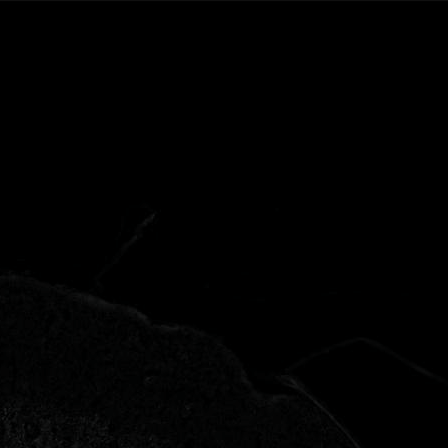

In [ ]:
from PIL import Image

unnormalized_image = (batch["pixel_values"][0].numpy() * np.array(ADE_STD)[:, None, None]) + np.array(ADE_MEAN)[:, None, None]
unnormalized_image = (unnormalized_image * 255).astype(np.uint8)
unnormalized_image = np.moveaxis(unnormalized_image, 0, -1)
unnormalized_image = Image.fromarray(unnormalized_image)
unnormalized_image

In [ ]:
[id2label[id] for id in torch.unique(batch["labels"][0]).tolist()]

['id_bg']

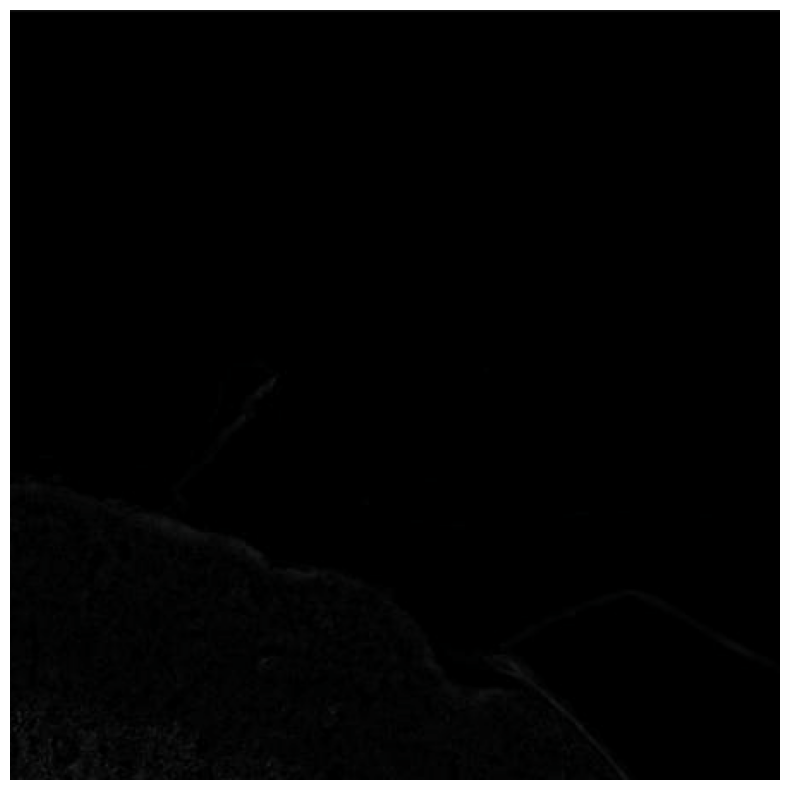

In [ ]:
visualize_map(unnormalized_image, batch["labels"][0].numpy())

## Define model

In [ ]:
import torch
from transformers import Dinov2Model, Dinov2PreTrainedModel
from transformers.modeling_outputs import SemanticSegmenterOutput

class LinearClassifier(torch.nn.Module):
    def __init__(self, in_channels, tokenW=32, tokenH=32, num_labels=1):
        super(LinearClassifier, self).__init__()

        self.in_channels = in_channels
        self.width = tokenW
        self.height = tokenH
        self.classifier = torch.nn.Conv2d(in_channels, num_labels, (1,1))


    def forward(self, embeddings):
        embeddings = embeddings.reshape(-1, self.height, self.width, self.in_channels)
        embeddings = embeddings.permute(0,3,1,2)

        return self.classifier(embeddings)


class Dinov2ForSemanticSegmentation(Dinov2PreTrainedModel):
  def __init__(self, config):
    super().__init__(config)

    self.dinov2 = Dinov2Model(config)
    self.classifier = LinearClassifier(config.hidden_size, 32, 32, config.num_labels)

  def forward(self, pixel_values, output_hidden_states=False, output_attentions=False, labels=None):
    # use frozen features
    outputs = self.dinov2(pixel_values,
                            output_hidden_states=output_hidden_states,
                            output_attentions=output_attentions)
    # get the patch embeddings - so we exclude the CLS token
    patch_embeddings = outputs.last_hidden_state[:,1:,:]

    # convert to logits and upsample to the size of the pixel values
    logits = self.classifier(patch_embeddings)
    logits = torch.nn.functional.interpolate(logits, size=pixel_values.shape[2:], mode="bilinear", align_corners=False)

    loss = None
    if labels is not None:
      # important: we're going to use 0 here as ignore index instead of the default -100
      # as we don't want the model to learn to predict background
      loss_fct = torch.nn.CrossEntropyLoss(ignore_index=0) # change it to -100
    #   loss = loss_fct(logits.squeeze(), labels.squeeze())
      loss = loss_fct(logits, labels)

    return SemanticSegmenterOutput(
        loss=loss,
        logits=logits,
        hidden_states=outputs.hidden_states,
        attentions=outputs.attentions,
    )

We can instantiate the model as follows:

In [ ]:
model = Dinov2ForSemanticSegmentation.from_pretrained("facebook/dinov2-base", id2label=id2label, num_labels=len(id2label))

/usr/local/lib/python3.10/dist-packages/huggingface_hub/utils/_token.py:89: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


config.json:   0%|          | 0.00/548 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/346M [00:00<?, ?B/s]

Some weights of Dinov2ForSemanticSegmentation were not initialized from the model checkpoint at facebook/dinov2-base and are newly initialized: ['classifier.classifier.bias', 'classifier.classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


Important: we don't want to train the DINOv2 backbone, only the linear classification head. Hence we don't want to track any gradients for the backbone parameters. This will greatly save us in terms of memory used:

In [ ]:
for name, param in model.named_parameters():
  if name.startswith("dinov2"):
    param.requires_grad = False

Let's perform a forward pass on a random batch, to verify the shape of the logits, verify we can calculate a loss:

In [ ]:
outputs = model(pixel_values=batch["pixel_values"], labels=batch["labels"])
print(outputs.logits.shape)
print(outputs.loss)

torch.Size([3, 11, 448, 448])
tensor(nan, grad_fn=<NllLoss2DBackward0>)


As can be seen, the logits are of shape (batch_size, num_labels, height, width). We can then just take the highest logit (score) for each pixel as the model's prediction.

## Train the model

We'll train the model in regular PyTorch fashion. We also use the mIoU (mean Intersection-over-Union) metric to evaluate the performance during training.

Note that I made this entire notebook just for demo purposes, I haven't done any hyperparameter tuning, so feel free to improve. You can also of course use other training frameworks (like the 🤗 Trainer, PyTorch Lightning, 🤗 Accelerate, ...).

In [ ]:
import evaluate

metric = evaluate.load("mean_iou")

In [ ]:
from torch.optim import AdamW
from tqdm.auto import tqdm

# training hyperparameters
# NOTE: I've just put some random ones here, not optimized at all
# feel free to experiment, see also DINOv2 paper
learning_rate = 5e-3
#epochs = 20
optimizer = AdamW(model.parameters(), lr=learning_rate)

# put model on GPU (set runtime to GPU in Google Colab)
device = "cuda" if torch.cuda.is_available() else "cpu"
print(device)
model.to(device)

cpu


Dinov2ForSemanticSegmentation(
  (dinov2): Dinov2Model(
    (embeddings): Dinov2Embeddings(
      (patch_embeddings): Dinov2PatchEmbeddings(
        (projection): Conv2d(3, 768, kernel_size=(14, 14), stride=(14, 14))
      )
      (dropout): Dropout(p=0.0, inplace=False)
    )
    (encoder): Dinov2Encoder(
      (layer): ModuleList(
        (0-11): 12 x Dinov2Layer(
          (norm1): LayerNorm((768,), eps=1e-06, elementwise_affine=True)
          (attention): Dinov2Attention(
            (attention): Dinov2SelfAttention(
              (query): Linear(in_features=768, out_features=768, bias=True)
              (key): Linear(in_features=768, out_features=768, bias=True)
              (value): Linear(in_features=768, out_features=768, bias=True)
              (dropout): Dropout(p=0.0, inplace=False)
            )
            (output): Dinov2SelfOutput(
              (dense): Linear(in_features=768, out_features=768, bias=True)
              (dropout): Dropout(p=0.0, inplace=False)
      

In [ ]:
from tqdm import tqdm

# Initialize the number of epochs
max_epochs = 1 # Set a high upper limit for epochs

# Early stopping parameters
patience = 5 # Number of epochs to wait for improvement
min_delta = 0.001  # Minimum change to qualify as an improvement
best_val_loss = np.inf
epochs_no_improve = 0

# Function to compute validation loss
def compute_validation_loss(model, val_dataloader, device):
    model.eval()
    val_loss = 0
    with torch.no_grad():
        for batch in val_dataloader:
            pixel_values = batch["pixel_values"].to(device)
            labels = batch["labels"].to(device)
            outputs = model(pixel_values, labels=labels)
            val_loss += outputs.loss.item()
    return val_loss / len(val_dataloader)

# Put model in training mode
model.train()

for epoch in range(max_epochs):
    print("Epoch:", epoch)
    for idx, batch in enumerate(tqdm(train_dataloader)):
        pixel_values = batch["pixel_values"].to(device)
        labels = batch["labels"].to(device)

        # Forward pass
        outputs = model(pixel_values, labels=labels)
        loss = outputs.loss

        # Print shapes
        print("Logits shape:", outputs.logits.shape)
        print("Labels shape:", labels.shape)

        loss.backward()
        optimizer.step()

        # Zero the parameter gradients
        optimizer.zero_grad()

        # Evaluate
        with torch.no_grad():
            predicted = outputs.logits.argmax(dim=1)

            # Note that the metric expects predictions + labels as numpy arrays
            metric.add_batch(predictions=predicted.detach().cpu().numpy(), references=labels.detach().cpu().numpy())

        # Let's print loss and metrics every batch
        if idx % 1 == 0:
            metrics = metric.compute(num_labels=len(id2label),
                                     ignore_index=0,
                                     reduce_labels=False)
            print("idx:", idx)
            print("Loss:", loss.item())
            print("Mean_iou:", metrics["mean_iou"])
            print("Mean accuracy:", metrics["mean_accuracy"])
            print("------------------------------------------")

    # Validation loss computation
    val_loss = compute_validation_loss(model, val_dataloader, device)
    print(f"Validation Loss: {val_loss}")

    # Early stopping check
    if val_loss < best_val_loss - min_delta:
        best_val_loss = val_loss
        epochs_no_improve = 0
    else:
        epochs_no_improve += 1
        if epochs_no_improve >= patience:
            print(f"Early stopping at epoch {epoch}")
            break


Epoch: 0


  0%|          | 0/39 [00:00<?, ?it/s]

Logits shape: torch.Size([3, 11, 448, 448])
Labels shape: torch.Size([3, 448, 448])


  3%|▎         | 1/39 [00:22<14:25, 22.76s/it]

idx: 0
Loss: 6.35909366607666
Mean_iou: 0.0
Mean accuracy: 0.0
------------------------------------------
Logits shape: torch.Size([3, 11, 448, 448])
Labels shape: torch.Size([3, 448, 448])


...

idx: 5
Loss: 3.2730226516723633
Mean_iou: 0.007717168146381395
Mean accuracy: 0.04711926920887097
------------------------------------------
Logits shape: torch.Size([3, 11, 448, 448])
Labels shape: torch.Size([3, 448, 448])


 18%|█▊        | 7/39 [02:34<11:53, 22.30s/it]

idx: 6
Loss: 11.842985153198242
Mean_iou: 0.0
Mean accuracy: 0.0
------------------------------------------


 21%|██        | 8/39 [02:55<11:16, 21.83s/it]

Logits shape: torch.Size([3, 11, 448, 448])
Labels shape: torch.Size([3, 448, 448])
idx: 7
Loss: nan
Mean_iou: nan
Mean accuracy: nan
------------------------------------------


## Inference

Once we've trained a model, we can perform inference on new images as follows:

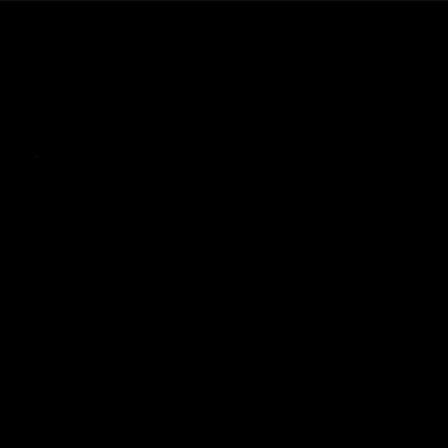

In [ ]:
from PIL import Image
test_image = dataset_dict["validation"][6]["image"]
test_image

In [ ]:
pixel_values = val_transform(image=np.array(test_image))["image"]
pixel_values = torch.tensor(pixel_values)
pixel_values = pixel_values.permute(2,0,1).unsqueeze(0) # convert to (batch_size, num_channels, height, width)
print(pixel_values.shape)

torch.Size([1, 3, 448, 448])


In [ ]:
# forward pass
with torch.no_grad():
  outputs = model(pixel_values.to(device))

In [ ]:
upsampled_logits = torch.nn.functional.interpolate(outputs.logits,
                                                   size=test_image.size[::-1],
                                                   mode="bilinear", align_corners=False)
predicted_map = upsampled_logits.argmax(dim=1)

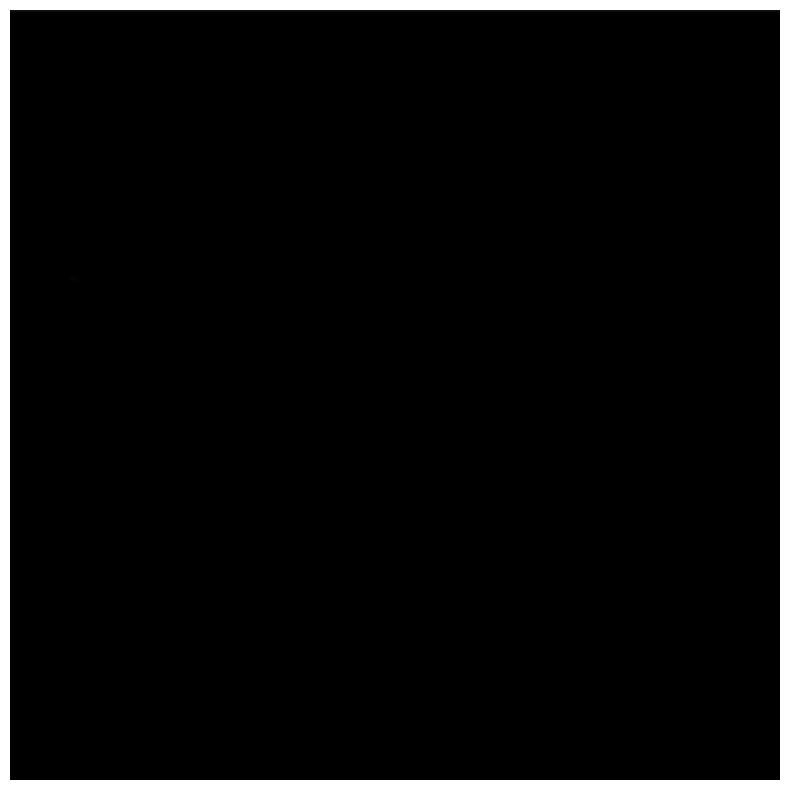

In [ ]:
visualize_map(dataset_dict["validation"][6]["image"], np.array(dataset_dict["validation"][6]["label"]))

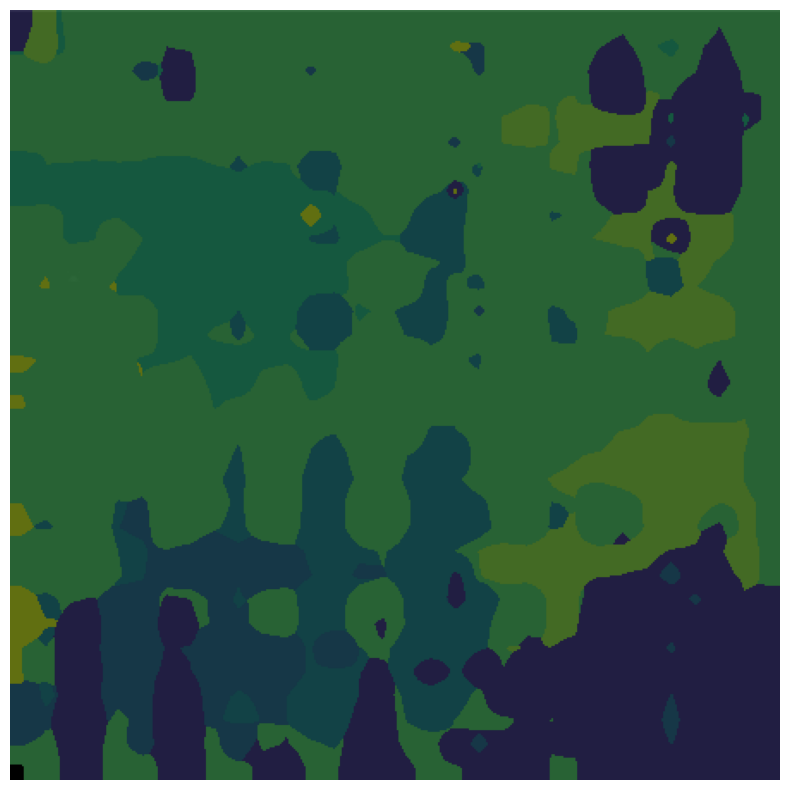

In [ ]:
visualize_map(test_image, predicted_map.squeeze().cpu())

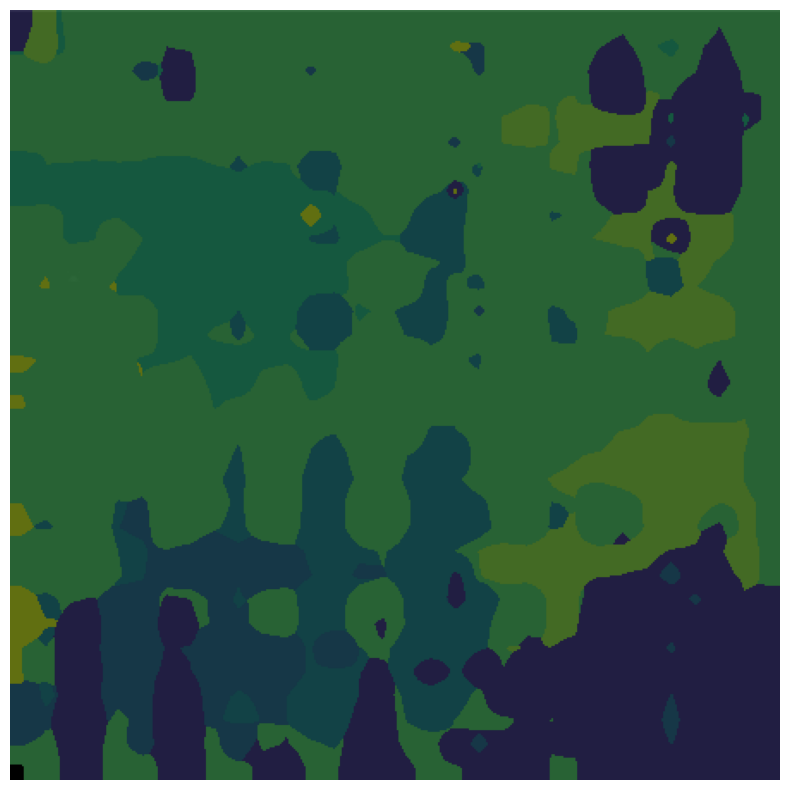

In [ ]:
visualize_map(test_image, predicted_map.squeeze().cpu())

In [ ]:
torch.save(model, 'model.pt')

In [ ]:
torch.save(model, 'model.pth')

In [ ]:
from google.colab import files
files.download('model.pt')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
from google.colab import files
files.download('model.pth')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>